In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
file_path = "/content/drive/MyDrive/DTCC/training/data_foundations/data/messy_ecommerce_100_rows.csv"

df = pd.read_csv(file_path)

df.head()

,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
0,ORD1001,C0016,Aarav Kumar,aarav.kumar95@gmail.com,2026-06-23,P102,Electronics,Bluetooth Headphones,2,1999,20,0.0,Net Banking,Delivered,Chennai,Tamil Nadu,600001,3198.4
1,ORD1002,C0002,Kabir Sharma,kabir.sharma26@gmail.com,2026-05-24,P110,Home,Desk Lamp,2,1299,0,0.0,Net Banking,Cancelled,Hyderabad,Telangana,500001,2598.0
2,ORD1003,C0052,Isha Kumar,NaN,2026-03-29,P104,Home,Water Bottle,2,349,20,80.0,Credit Card,Shipped,Hyderabad,Telangana,500001,638.4
3,ORD1004,C0025,Diya Reddy,diya.reddy6@gmail.com,2026-07-26,P106,Grocery,Coffee Powder,3,450,5,60.0,COD,Returned,Hyderabad,Telangana,500001,1342.5
4,ORD1005,C0006,Nikhil Das,nikhil.das25@gmail.com,2026-05-28,P102,Electronics,Bluetooth Headphones,NaN,1999,20,60.0,UPI,Delivered,Delhi,Delhi,110001,4857.6


In [38]:
df.shape

(100, 18)

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        99 non-null     object 
 1   customer_id     99 non-null     object 
 2   customer_name   99 non-null     object 
 3   email           99 non-null     object 
 4   order_date      99 non-null     object 
 5   product_id      100 non-null    object 
 6   category        100 non-null    object 
 7   product_name    100 non-null    object 
 8   quantity        99 non-null     object 
 9   unit_price      99 non-null     object 
 10  discount_pct    99 non-null     object 
 11  shipping_fee    99 non-null     float64
 12  payment_method  100 non-null    object 
 13  order_status    100 non-null    object 
 14  city            100 non-null    object 
 15  state           99 non-null     object 
 16  postal_code     100 non-null    object 
 17  total_amount    99 non-null     obje

In [40]:
df.describe()

,shipping_fee
count,99.000000
mean,43.636364
std,31.084301
min,-20.000000
25%,0.000000
50%,60.000000
75%,60.000000
max,80.000000


In [41]:
df.columns

Index(['order_id', 'customer_id', 'customer_name', 'email', 'order_date',
       'product_id', 'category', 'product_name', 'quantity', 'unit_price',
       'discount_pct', 'shipping_fee', 'payment_method', 'order_status',
       'city', 'state', 'postal_code', 'total_amount'],
      dtype='object')

# Task 1 : Identify Missing Values

In [42]:
print(df.isnull().sum())

order_id          1
customer_id       1
customer_name     1
email             1
order_date        1
product_id        0
category          0
product_name      0
quantity          1
unit_price        1
discount_pct      1
shipping_fee      1
payment_method    0
order_status      0
city              0
state             1
postal_code       0
total_amount      1
dtype: int64


In [43]:
df_clean = df.copy()
df_clean = df_clean.dropna(subset=["order_id"])

In [44]:
df_clean["customer_name"] = df_clean["customer_name"].fillna("Unknown")
df_clean["email"] = df_clean["email"].fillna("Not Available")
df_clean["state"] = df_clean["state"].fillna("Unknown")

In [45]:
print("Missing Values After Basic Cleaning:")
print(df_clean.isnull().sum())

Missing Values After Basic Cleaning:
order_id          0
customer_id       1
customer_name     0
email             0
order_date        1
product_id        0
category          0
product_name      0
quantity          1
unit_price        1
discount_pct      1
shipping_fee      1
payment_method    0
order_status      0
city              0
state             0
postal_code       0
total_amount      1
dtype: int64


# Task 2 : Identify and Remove Duplicate Orders

In [46]:

duplicate_orders = df_clean[
    df_clean.duplicated(subset=["order_id"], keep=False)
]


In [47]:

print("Orders with Repeated Order IDs:")
display(duplicate_orders.sort_values("order_id"))

Orders with Repeated Order IDs:


,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
9,ORD1010,C0009,Rohan Kumar,rohan.kumar75@gmail.com,2026-07-11,P108,Electronics,USB-C Cable,5,299,15,60.0,COD,Returned,Chennai,Tamil Nadu,600001,1330.75
59,ORD1010,C0009,Rohan Kumar,rohan.kumar75@gmail.com,2026-07-11,P108,Electronics,USB-C Cable,5,299,15,60.0,COD,Returned,Chennai,Tamil Nadu,600001,1330.75
29,ORD1030,C0001,Nikhil Reddy,nikhil.reddy69@gmail.com,2026-01-19,P106,Grocery,Coffee Powder,5,450,15,0.0,Credit Card,Returned,Mumbai,Maharashtra,400001,1912.5
79,ORD1030,C0001,Nikhil Reddy,nikhil.reddy69@gmail.com,2026-01-19,P106,Grocery,Coffee Powder,5,450,15,0.0,Credit Card,Returned,Mumbai,Maharashtra,400001,1912.5
39,ORD1040,C0018,Kabir Rao,kabir.rao69@gmail.com,2026-06-23,P104,Home,Water Bottle,3,349,5,80.0,Debit Card,Delivered,Hyderabad,Telangana,500001,1074.65
89,ORD1040,C0036,Vikram Sharma,vikram.sharma16@gmail.com,2026-04-29,P103,Fashion,Cotton T-Shirt,1,599,0,0.0,Credit Card,Cancelled,Mumbai,Maharashtra,400001,599.0


In [48]:

print("Exact Duplicate Rows:", df_clean.duplicated().sum())

Exact Duplicate Rows: 2


In [49]:
df_clean = df_clean.drop_duplicates().copy()

In [50]:
conflicting_orders = df_clean[
    df_clean.duplicated(subset=["order_id"], keep=False)
]

print("Conflicting Orders for Investigation:")
display(conflicting_orders)

Conflicting Orders for Investigation:


,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
39,ORD1040,C0018,Kabir Rao,kabir.rao69@gmail.com,2026-06-23,P104,Home,Water Bottle,3,349,5,80.0,Debit Card,Delivered,Hyderabad,Telangana,500001,1074.65
89,ORD1040,C0036,Vikram Sharma,vikram.sharma16@gmail.com,2026-04-29,P103,Fashion,Cotton T-Shirt,1,599,0,0.0,Credit Card,Cancelled,Mumbai,Maharashtra,400001,599.0


In [51]:

print("Rows After Removing Exact Duplicates:", len(df_clean))

Rows After Removing Exact Duplicates: 97


In [52]:
conflicting_orders.to_csv(
    "conflicting_orders.csv",
    index=False
)

In [53]:
df_clean = df_clean[
    ~df_clean.duplicated(subset=["order_id"], keep=False)
].copy()

print("Rows After Resolving Duplicate Issues:", len(df_clean))

Rows After Resolving Duplicate Issues: 95


# Task 3 : Identify the Highest-Priced Product

In [54]:

# Convert prices into numeric format
df_clean["unit_price"] = pd.to_numeric(
    df_clean["unit_price"]
    .astype("string")
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

In [55]:
valid_products = df_clean[
    df_clean["unit_price"].notna() &
    (df_clean["unit_price"] >= 0)
]

In [56]:
highest_product = valid_products.loc[
    valid_products["unit_price"].idxmax()
]

In [57]:

print("Highest Priced Product:")
print("Product:", highest_product["product_name"])
print("Unit Price: ₹", highest_product["unit_price"])
print("Category:", highest_product["category"])

Highest Priced Product:
Product: Running Shoes
Unit Price: ₹ 2499
Category: Fashion


In [58]:

top_products = (
    valid_products
    .groupby("product_name")["unit_price"]
    .max()
    .sort_values(ascending=False)
    .head(5)
)

display(top_products)




,unit_price
product_name,
Running Shoes,2499
Bluetooth Headphones,1999
Coffee Powder,1999
Desk Lamp,1299
Python Basics,1299


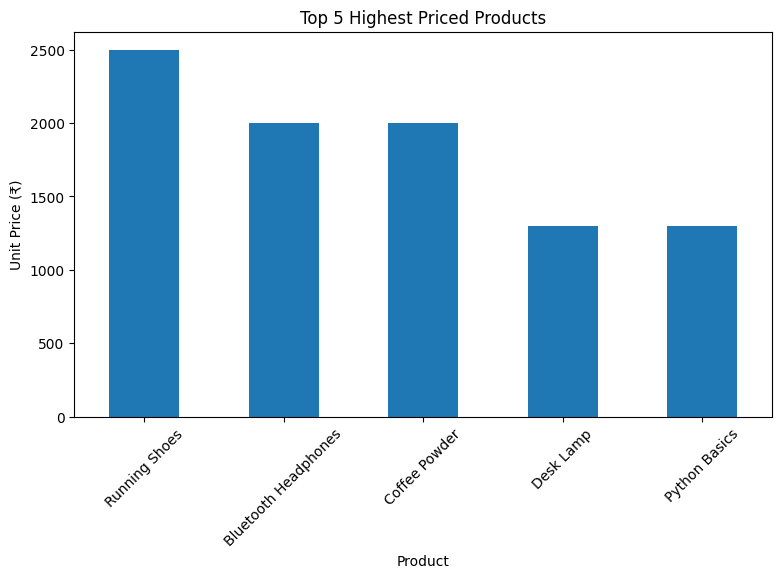

In [59]:
top_products.plot(
    kind="bar",
    title="Top 5 Highest Priced Products",
    figsize=(9, 5)
)

plt.xlabel("Product")
plt.ylabel("Unit Price (₹)")
plt.xticks(rotation=45)
plt.show()

# Task 4 : City-wise Revenue Analysis

In [60]:
df_clean["city"] = (
    df_clean["city"]
    .astype("string")
    .str.strip()
    .str.title()
)

In [61]:
df_clean["city"] = df_clean["city"].replace({
    "Hyd": "Hyderabad",
    "Chenn Ai": "Chennai",
    "Bangalore": "Bengaluru"
})

In [62]:
df_clean["order_status"] = (
    df_clean["order_status"]
    .astype("string")
    .str.strip()
    .str.title()
)

In [63]:
numeric_columns = [
    "quantity",
    "discount_pct",
    "shipping_fee",
    "total_amount"
]

In [64]:
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

display(df_clean.head())

,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount
0,ORD1001,C0016,Aarav Kumar,aarav.kumar95@gmail.com,2026-06-23,P102,Electronics,Bluetooth Headphones,2.0,1999,20.0,0.0,Net Banking,Delivered,Chennai,Tamil Nadu,600001,3198.4
1,ORD1002,C0002,Kabir Sharma,kabir.sharma26@gmail.com,2026-05-24,P110,Home,Desk Lamp,2.0,1299,0.0,0.0,Net Banking,Cancelled,Hyderabad,Telangana,500001,2598.0
2,ORD1003,C0052,Isha Kumar,Not Available,2026-03-29,P104,Home,Water Bottle,2.0,349,20.0,80.0,Credit Card,Shipped,Hyderabad,Telangana,500001,638.4
3,ORD1004,C0025,Diya Reddy,diya.reddy6@gmail.com,2026-07-26,P106,Grocery,Coffee Powder,3.0,450,5.0,60.0,COD,Returned,Hyderabad,Telangana,500001,1342.5
4,ORD1005,C0006,Nikhil Das,nikhil.das25@gmail.com,2026-05-28,P102,Electronics,Bluetooth Headphones,NaN,1999,20.0,60.0,UPI,Delivered,Delhi,Delhi,110001,4857.6


In [65]:
valid_data = df_clean[
    (df_clean["quantity"] > 0) &
    (df_clean["quantity"] % 1 == 0) &
    (df_clean["unit_price"] >= 0) &
    (df_clean["discount_pct"].between(0, 100)) &
    (df_clean["shipping_fee"] >= 0)
].copy()

In [66]:
valid_data["calculated_revenue"] = (
    valid_data["quantity"] *
    valid_data["unit_price"] *
    (1 - valid_data["discount_pct"] / 100)
    + valid_data["shipping_fee"]
)

In [67]:
sales_data = valid_data[
    valid_data["order_status"] == "Delivered"
].copy()

In [68]:
city_revenue = (
    sales_data.groupby("city")["calculated_revenue"]
    .sum()
    .sort_values(ascending=False)
)

In [69]:
print("City-wise Revenue:")
display(city_revenue)

print("Total Revenue: ₹", round(city_revenue.sum(), 2))

City-wise Revenue:


,calculated_revenue
city,
Hyderabad,11182.4
Pune,9948.4
Delhi,8036.0
Mumbai,7465.7
Chennai,6876.6
Bengaluru,593.3


Total Revenue: ₹ 44102.4


# Task 5 : Export Cleaned Dataset

In [70]:
valid_data.to_csv(
    "cleaned_ecommerce.csv",
    index=False
)

In [71]:
city_revenue.to_csv(
    "city_revenue_report.csv",
    header=["Revenue"]
)

In [72]:
print("Cleaned Dataset Saved Successfully!")
print("Revenue Report Saved Successfully!")

print("Original Records:", len(df))
print("Cleaned Records:", len(valid_data))

display(valid_data.head())

Cleaned Dataset Saved Successfully!
Revenue Report Saved Successfully!
Original Records: 100
Cleaned Records: 81


,order_id,customer_id,customer_name,email,order_date,product_id,category,product_name,quantity,unit_price,discount_pct,shipping_fee,payment_method,order_status,city,state,postal_code,total_amount,calculated_revenue
0,ORD1001,C0016,Aarav Kumar,aarav.kumar95@gmail.com,2026-06-23,P102,Electronics,Bluetooth Headphones,2.0,1999,20.0,0.0,Net Banking,Delivered,Chennai,Tamil Nadu,600001,3198.4,3198.4
1,ORD1002,C0002,Kabir Sharma,kabir.sharma26@gmail.com,2026-05-24,P110,Home,Desk Lamp,2.0,1299,0.0,0.0,Net Banking,Cancelled,Hyderabad,Telangana,500001,2598.0,2598.0
2,ORD1003,C0052,Isha Kumar,Not Available,2026-03-29,P104,Home,Water Bottle,2.0,349,20.0,80.0,Credit Card,Shipped,Hyderabad,Telangana,500001,638.4,638.4
3,ORD1004,C0025,Diya Reddy,diya.reddy6@gmail.com,2026-07-26,P106,Grocery,Coffee Powder,3.0,450,5.0,60.0,COD,Returned,Hyderabad,Telangana,500001,1342.5,1342.5
5,ORD1006,C0006,Kiran Kumar,kiran.kumar82@gmail.com,2026-04-27,P104,Home,Water Bottle,1.0,349,10.0,60.0,Debit Card,Shipped,Chennai,Tamil Nadu,600001,374.1,374.1
